In [77]:
%matplotlib inline
import numpy as np
import torch
torch.set_printoptions(edgeitems=2, linewidth=75)

**TMEP Data List**

In [78]:
t_c = [0.5,  14.0, 15.0, 28.0, 11.0,  8.0,  3.0, -4.0,  6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

t_un = (t_u - t_u.mean()) / (t_u - t_u.mean()).abs().max()   #normalized t_un


**Auto Grad: Computing the Gradient Automatically**

**Problem 1a**

In [79]:
def model(t_u, w2, w1, b):
    return w2 * t_u**2 + w1 * t_u + b  #nonlinear model

In [80]:
def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c)**2
    return squared_diffs.mean()

**Loss Calculations**

In [81]:
w2 = torch.ones(())
w1 = torch.ones(())
b = torch.zeros(())

t_p = model(t_u, w2, w1, b)
t_p


tensor([1310.1901, 3180.7100, 3445.4399, 6789.5103, 3225.9900, 2440.1101,
        1183.1101,  497.0399, 2390.9600, 3708.5601, 4746.9600])

**Checks the value of the loss**

In [82]:
loss = loss_fn(t_p, t_c)
loss

tensor(11709471.)

**Auto Grad**

In [83]:
params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
loss = loss_fn(model(t_u, *params), t_c)
loss.backward()
params.grad

tensor([2.3149e+07, 3.6181e+05, 5.9642e+03])

**Problem 1b**

In [84]:
def training_loop(n_epochs, learning_rate, params, t_u, t_c):
    for epoch in range(1, n_epochs + 1):
        if params.grad is not None:  # <1>
            params.grad.zero_()

        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)
        loss.backward()

        with torch.no_grad():  # <2>
            params -= learning_rate * params.grad

        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, float(loss)))

    return params

**Learning rate at 0.1**

In [85]:
training_loop(
    n_epochs = 5000,
    learning_rate = 0.1,
    params = torch.tensor([1.0, 1.0, 0.0],
                          requires_grad=True),
    t_u = t_un,
    t_c = t_c
)

Epoch 500, Loss 2.090720
Epoch 1000, Loss 2.090720
Epoch 1500, Loss 2.090720
Epoch 2000, Loss 2.090720
Epoch 2500, Loss 2.090720
Epoch 3000, Loss 2.090720
Epoch 3500, Loss 2.090720
Epoch 4000, Loss 2.090720
Epoch 4500, Loss 2.090720
Epoch 5000, Loss 2.090720


tensor([ 2.5644, 16.2792,  9.7710], requires_grad=True)

**Learning rate at 1e-2**

In [86]:
training_loop(
    n_epochs = 5000,
    learning_rate = 1e-2,
    params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True), # <1>
    t_u = t_un, # <2>
    t_c = t_c)

Epoch 500, Loss 2.316072
Epoch 1000, Loss 2.091575
Epoch 1500, Loss 2.090735
Epoch 2000, Loss 2.090721
Epoch 2500, Loss 2.090720
Epoch 3000, Loss 2.090719
Epoch 3500, Loss 2.090720
Epoch 4000, Loss 2.090720
Epoch 4500, Loss 2.090720
Epoch 5000, Loss 2.090720


tensor([ 2.5645, 16.2792,  9.7709], requires_grad=True)

**Learning rate at 1e-3**

In [87]:
training_loop(
    n_epochs = 5000,
    learning_rate = 1e-3,
    params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True),

    t_u = t_un,
    t_c = t_c
)

Epoch 500, Loss 51.974888
Epoch 1000, Loss 25.033588
Epoch 1500, Loss 14.468345
Epoch 2000, Loss 9.021024
Epoch 2500, Loss 6.001053
Epoch 3000, Loss 4.300717
Epoch 3500, Loss 3.340315
Epoch 4000, Loss 2.797477
Epoch 4500, Loss 2.490588
Epoch 5000, Loss 2.317055


tensor([ 2.7250, 15.4018,  9.7143], requires_grad=True)

**Learning rate at 1e-4**

In [88]:
training_loop(
    n_epochs = 5000,
    learning_rate = 1e-4,
    params = torch.tensor([1.0, 1.0, 0.0],
                          requires_grad=True),
    t_u = t_un,
    t_c = t_c
)

Epoch 500, Loss 148.623398
Epoch 1000, Loss 128.874405
Epoch 1500, Loss 112.500465
Epoch 2000, Loss 98.867241
Epoch 2500, Loss 87.463249
Epoch 3000, Loss 77.875862
Epoch 3500, Loss 69.772179
Epoch 4000, Loss 62.883118
Epoch 4500, Loss 56.991211
Epoch 5000, Loss 51.920528


tensor([2.6691, 4.7746, 6.2540], requires_grad=True)

**Problem 1c**

The best Non-linear model is based on 0.1

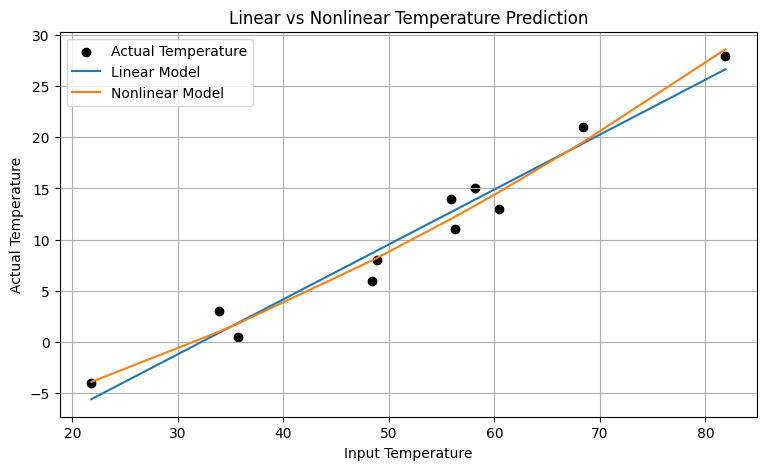

In [89]:
import matplotlib.pyplot as plt

# Based off of original linear model from lecture
linear_params = torch.tensor([5.3671, -17.3012])
t_linear = linear_params[0] * (0.1 * t_u) + linear_params[1]

# Best nonlinear model based on a learning rate of 0.1
nonlinear_params = torch.tensor([2.5644, 16.2792, 9.7710])

t_scaled = (t_u - t_u.mean()) / (t_u - t_u.mean()).abs().max()
t_nonlinear = model(t_scaled, *nonlinear_params)

# Sort x-values so prediction lines display correctly
sort_idx = torch.argsort(t_u)



plt.figure(figsize=(9, 5))
# Actual Temperature t_c plotted
plt.scatter(t_u.numpy(), t_c.numpy(),
            label='Actual Temperature', color='black')
# Plotting linear model
plt.plot(t_u[sort_idx].numpy(),
         t_linear[sort_idx].numpy(),
         label='Linear Model')
#plotting Nonlinear Model we put together
plt.plot(t_u[sort_idx].numpy(),
         t_nonlinear[sort_idx].numpy(),
         label='Nonlinear Model')

plt.xlabel('Input Temperature')
plt.ylabel('Actual Temperature')
plt.title('Linear vs Nonlinear Temperature Prediction')
plt.legend()
plt.grid(True)
plt.show()


**Problem 2a**

In [90]:
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

url = 'https://raw.githubusercontent.com/iperezv-cpu/ML/refs/heads/main/Housing.csv'
# Load housing dataset
housing = pd.read_csv(url)

# Display first five rows
housing.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [91]:
# List of variables to map

varlist =  ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']

# Defining the map function
def binary_map(x):
    return x.map({'yes': 1, 'no': 0})

# Applying the function to the housing list
housing[varlist] = housing[varlist].apply(binary_map)
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished


In [92]:
X = housing[
    ['area',
     'bedrooms',
     'bathrooms',
     'stories',
     'parking'
     ]
].values

Y = housing['price'].values
print(X.shape)
print(Y.shape)

(545, 5)
(545,)


In [93]:
from sklearn.model_selection import train_test_split

# We specify this so that the train and test data set always have the same rows, respectively
np.random.seed(0)
X_train, X_val, y_train, y_val = train_test_split(X, Y, train_size = 0.8, test_size = 0.2, random_state = 42)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 436
Validation samples: 109


**Standardize the X**

In [94]:

# Standardize X using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Convert X data to PyTorch tensors
X_train_t = torch.tensor(X_train_scaled,
                         dtype=torch.float32)

X_val_t = torch.tensor(X_val_scaled,
                       dtype=torch.float32)

# Scale prices to improve gradient descent
price_scale = y_train.mean()

y_train_t = torch.tensor(y_train / price_scale,
                         dtype=torch.float32)

y_val_t = torch.tensor(y_val / price_scale,
                       dtype=torch.float32)

print(X_train_t.shape)
print(X_val_t.shape)


torch.Size([436, 5])
torch.Size([109, 5])


**Training and prediction**

In [95]:
def housing_model(X, params):
    return X @ params[:5] + params[5]

In [96]:

def housing_training_loop(n_epochs, optimizer, params,
                          X_train_t, y_train_t,
                          X_val_t, y_val_t):

    for epoch in range(1, n_epochs + 1):

        # Forward pass
        y_pred = housing_model(X_train_t, params)
        train_loss = loss_fn(y_pred, y_train_t)

        # Gradient descent
        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        # Report every 500 epochs
        if epoch % 500 == 0:

            with torch.no_grad():
                y_val_pred = housing_model(X_val_t, params)
                val_loss = loss_fn(y_val_pred, y_val_t)

                ss_res = torch.sum((y_val_t - y_val_pred)**2)
                ss_tot = torch.sum((y_val_t - y_val_t.mean())**2)
                val_r2 = 1 - ss_res / ss_tot

            print(f"Epoch {epoch}, "
                  f"Training Loss {train_loss.item():.6f}, "
                  f"Validation Loss {val_loss.item():.6f}, "
                  f"Validation R2 {val_r2.item():.4f}")

    return params


**Problem 2b**

**Learning rate**

In [97]:
import torch
import torch.nn as nn
import torch.optim as optim

In [98]:

# Five weights and one bias
params = torch.tensor([0., 0., 0., 0., 0., 0.], requires_grad=True)

learning_rate = 1e-1
optimizer = optim.SGD([params], lr=learning_rate)

housing_training_loop(
    n_epochs=5000,
    optimizer=optimizer,
    params=params,
    X_train_t=X_train_t,
    y_train_t=y_train_t,
    X_val_t=X_val_t,
    y_val_t=y_val_t
)


Epoch 500, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 1000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 1500, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 2000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 2500, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 3000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 3500, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 4000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 4500, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 5000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464


tensor([0.1445, 0.0240, 0.1201, 0.0902, 0.0613, 1.0000],
       requires_grad=True)

In [99]:
# Five weights and one bias
params = torch.tensor([0., 0., 0., 0., 0., 0.], requires_grad=True)

learning_rate = 1e-2
optimizer = optim.SGD([params], lr=learning_rate)

housing_training_loop(
    n_epochs=5000,
    optimizer=optimizer,
    params=params,
    X_train_t=X_train_t,
    y_train_t=y_train_t,
    X_val_t=X_val_t,
    y_val_t=y_val_t
)

Epoch 500, Training Loss 0.060945, Validation Loss 0.103506, Validation R2 0.5464
Epoch 1000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 1500, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 2000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 2500, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 3000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 3500, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 4000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 4500, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464
Epoch 5000, Training Loss 0.060945, Validation Loss 0.103502, Validation R2 0.5464


tensor([0.1445, 0.0240, 0.1201, 0.0902, 0.0613, 1.0000],
       requires_grad=True)

In [100]:
# Five weights and one bias
params = torch.tensor([0., 0., 0., 0., 0., 0.], requires_grad=True)

learning_rate = 1e-3
optimizer = optim.SGD([params], lr=learning_rate)

housing_training_loop(
    n_epochs=5000,
    optimizer=optimizer,
    params=params,
    X_train_t=X_train_t,
    y_train_t=y_train_t,
    X_val_t=X_val_t,
    y_val_t=y_val_t
)

Epoch 500, Training Loss 0.199938, Validation Loss 0.272060, Validation R2 -0.1923
Epoch 1000, Training Loss 0.079788, Validation Loss 0.130689, Validation R2 0.4273
Epoch 1500, Training Loss 0.063561, Validation Loss 0.108940, Validation R2 0.5226
Epoch 2000, Training Loss 0.061321, Validation Loss 0.104895, Validation R2 0.5403
Epoch 2500, Training Loss 0.061002, Validation Loss 0.103939, Validation R2 0.5445
Epoch 3000, Training Loss 0.060955, Validation Loss 0.103657, Validation R2 0.5457
Epoch 3500, Training Loss 0.060947, Validation Loss 0.103562, Validation R2 0.5461
Epoch 4000, Training Loss 0.060945, Validation Loss 0.103526, Validation R2 0.5463
Epoch 4500, Training Loss 0.060945, Validation Loss 0.103512, Validation R2 0.5464
Epoch 5000, Training Loss 0.060945, Validation Loss 0.103507, Validation R2 0.5464


tensor([0.1444, 0.0242, 0.1200, 0.0901, 0.0613, 1.0000],
       requires_grad=True)

In [101]:
# Five weights and one bias
params = torch.tensor([0., 0., 0., 0., 0., 0.], requires_grad=True)

learning_rate = 1e-4
optimizer = optim.SGD([params], lr=learning_rate)

housing_training_loop(
    n_epochs=5000,
    optimizer=optimizer,
    params=params,
    X_train_t=X_train_t,
    y_train_t=y_train_t,
    X_val_t=X_val_t,
    y_val_t=y_val_t
)

Epoch 500, Training Loss 0.934728, Validation Loss 1.121363, Validation R2 -3.9143
Epoch 1000, Training Loss 0.770015, Validation Loss 0.930155, Validation R2 -3.0764
Epoch 1500, Training Loss 0.637238, Validation Loss 0.776525, Validation R2 -2.4031
Epoch 2000, Training Loss 0.529935, Validation Loss 0.652691, Validation R2 -1.8604
Epoch 2500, Training Loss 0.443035, Validation Loss 0.552589, Validation R2 -1.4217
Epoch 3000, Training Loss 0.372530, Validation Loss 0.471461, Validation R2 -1.0662
Epoch 3500, Training Loss 0.315238, Validation Loss 0.405555, Validation R2 -0.7773
Epoch 4000, Training Loss 0.268622, Validation Loss 0.351901, Validation R2 -0.5422
Epoch 4500, Training Loss 0.230650, Validation Loss 0.308135, Validation R2 -0.3504
Epoch 5000, Training Loss 0.199691, Validation Loss 0.272371, Validation R2 -0.1937


tensor([0.1022, 0.0478, 0.0920, 0.0681, 0.0611, 0.6322],
       requires_grad=True)

The best liner model is at a learning rate of 0.1 and 0.01

**Problem 3**

In [102]:
housing['furnishingstatus'] = housing['furnishingstatus'].map({
    'unfurnished': 0,
    'semi-furnished': 1,
    'furnished': 2
})
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,2
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,2
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,2
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,2


In [103]:
X3 = housing[
    ['area',
     'bedrooms',
     'bathrooms',
     'stories',
     'mainroad',
     'guestroom',
     'basement',
     'hotwaterheating',
     'airconditioning',
     'parking',
     'prefarea',
     'furnishingstatus'

     ]
].values

y = housing['price'].values

print(X3.shape)
print(Y.shape)

(545, 12)
(545,)


In [104]:
from sklearn.model_selection import train_test_split

# We specify this so that the train and test data set always have the same rows, respectively
np.random.seed(0)
X3_train, X3_val, y3_train, y3_val = train_test_split(X3, Y, train_size = 0.8, test_size = 0.2, random_state = 42)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 436
Validation samples: 109


**Standardization**

In [105]:

# Standardize X using training data only
scaler = StandardScaler()

X3_train_scaled = scaler.fit_transform(X3_train)
X3_val_scaled = scaler.transform(X3_val)

# Convert X data to PyTorch tensors
X3_train_t = torch.tensor(X3_train_scaled,
                         dtype=torch.float32)

X3_val_t = torch.tensor(X3_val_scaled,
                       dtype=torch.float32)

# Scale prices to improve gradient descent
price_scale = y_train.mean()

y3_train_t = torch.tensor(y3_train / price_scale,
                         dtype=torch.float32)

y3_val_t = torch.tensor(y3_val / price_scale,
                       dtype=torch.float32)

print(X3_train_t.shape)
print(X3_val_t.shape)

torch.Size([436, 12])
torch.Size([109, 12])


**training**

In [106]:
def housing_model3(X3, params):
    return X3 @ params[:12] + params[12]

In [107]:

def housing_training_loop3(n_epochs, optimizer, params,
                          X3_train_t, y3_train_t,
                          X3_val_t, y3_val_t):

    for epoch in range(1, n_epochs + 1):


        # Forward pass
        y3_pred = housing_model3(X3_train_t, params)
        train3_loss = loss_fn(y3_pred, y3_train_t)

        # Gradient descent
        optimizer.zero_grad()
        train3_loss.backward()
        optimizer.step()



        # Report every 500 epochs
        if epoch % 500 == 0:

            with torch.no_grad():
                y3_val_pred = housing_model3(X3_val_t, params)
                val3_loss = loss_fn(y3_val_pred, y3_val_t)

                ss_res = torch.sum((y3_val_t - y3_val_pred)**2)
                ss_tot = torch.sum((y3_val_t - y3_val_t.mean())**2)
                val_r2 = 1 - ss_res / ss_tot

            print(f"Epoch {epoch}, "
                  f"Training Loss {train3_loss.item():.6f}, "
                  f"Validation Loss {val3_loss.item():.6f}, "
                  f"Validation R2 {val_r2.item():.4f}")



    return params


**Learning Rate**

In [108]:
# Twelve weights and one bias
params = torch.tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True)

learning_rate = 1e-1
optimizer = optim.SGD([params], lr=learning_rate)

housing_training_loop3(
    n_epochs=5000,
    optimizer=optimizer,
    params=params,
    X3_train_t=X3_train_t,
    y3_train_t=y3_train_t,
    X3_val_t=X3_val_t,
    y3_val_t=y3_val_t
)


Epoch 500, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 1000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 1500, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 2000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 2500, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 3000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 3500, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 4000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 4500, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 5000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495


tensor([0.1103, 0.0125, 0.1112, 0.0740, 0.0272, 0.0190, 0.0400, 0.0320,
        0.0770, 0.0410, 0.0567, 0.0336, 1.0000], requires_grad=True)

In [109]:
# Twelve weights and one bias
params = torch.tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True)

learning_rate = 1e-2
optimizer = optim.SGD([params], lr=learning_rate)

housing_training_loop3(
    n_epochs=5000,
    optimizer=optimizer,
    params=params,
    X3_train_t=X3_train_t,
    y3_train_t=y3_train_t,
    X3_val_t=X3_val_t,
    y3_val_t=y3_val_t
)


Epoch 500, Training Loss 0.043786, Validation Loss 0.079970, Validation R2 0.6495
Epoch 1000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 1500, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 2000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 2500, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 3000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 3500, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 4000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 4500, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495
Epoch 5000, Training Loss 0.043785, Validation Loss 0.079984, Validation R2 0.6495


tensor([0.1103, 0.0125, 0.1112, 0.0740, 0.0272, 0.0190, 0.0400, 0.0320,
        0.0770, 0.0410, 0.0567, 0.0336, 1.0000], requires_grad=True)

In [110]:
# Twelve weights and one bias
params = torch.tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True)

learning_rate = 1e-3
optimizer = optim.SGD([params], lr=learning_rate)

housing_training_loop3(
    n_epochs=5000,
    optimizer=optimizer,
    params=params,
    X3_train_t=X3_train_t,
    y3_train_t=y3_train_t,
    X3_val_t=X3_val_t,
    y3_val_t=y3_val_t
)


Epoch 500, Training Loss 0.181763, Validation Loss 0.246011, Validation R2 -0.0781
Epoch 1000, Training Loss 0.062657, Validation Loss 0.106521, Validation R2 0.5332
Epoch 1500, Training Loss 0.046445, Validation Loss 0.084965, Validation R2 0.6276
Epoch 2000, Training Loss 0.044186, Validation Loss 0.081036, Validation R2 0.6449
Epoch 2500, Training Loss 0.043856, Validation Loss 0.080189, Validation R2 0.6486
Epoch 3000, Training Loss 0.043801, Validation Loss 0.079992, Validation R2 0.6494
Epoch 3500, Training Loss 0.043790, Validation Loss 0.079953, Validation R2 0.6496
Epoch 4000, Training Loss 0.043787, Validation Loss 0.079954, Validation R2 0.6496
Epoch 4500, Training Loss 0.043786, Validation Loss 0.079962, Validation R2 0.6496
Epoch 5000, Training Loss 0.043786, Validation Loss 0.079970, Validation R2 0.6495


tensor([0.1101, 0.0129, 0.1111, 0.0735, 0.0274, 0.0193, 0.0396, 0.0320,
        0.0772, 0.0410, 0.0567, 0.0337, 1.0000], requires_grad=True)

In [111]:
# Twelve weights and one bias
params = torch.tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True)

learning_rate = 1e-4
optimizer = optim.SGD([params], lr=learning_rate)

housing_training_loop3(
    n_epochs=5000,
    optimizer=optimizer,
    params=params,
    X3_train_t=X3_train_t,
    y3_train_t=y3_train_t,
    X3_val_t=X3_val_t,
    y3_val_t=y3_val_t
)


Epoch 500, Training Loss 0.922447, Validation Loss 1.105236, Validation R2 -3.8436
Epoch 1000, Training Loss 0.752000, Validation Loss 0.906023, Validation R2 -2.9706
Epoch 1500, Training Loss 0.616937, Validation Loss 0.748825, Validation R2 -2.2817
Epoch 2000, Training Loss 0.509067, Validation Loss 0.623763, Validation R2 -1.7336
Epoch 2500, Training Loss 0.422387, Validation Loss 0.523601, Validation R2 -1.2947
Epoch 3000, Training Loss 0.352404, Validation Loss 0.442940, Validation R2 -0.9412
Epoch 3500, Training Loss 0.295698, Validation Loss 0.377690, Validation R2 -0.6552
Epoch 4000, Training Loss 0.249624, Validation Loss 0.324710, Validation R2 -0.4230
Epoch 4500, Training Loss 0.212110, Validation Loss 0.281560, Validation R2 -0.2339
Epoch 5000, Training Loss 0.181518, Validation Loss 0.246322, Validation R2 -0.0795


tensor([0.0827, 0.0393, 0.0833, 0.0575, 0.0365, 0.0303, 0.0284, 0.0190,
        0.0669, 0.0479, 0.0446, 0.0373, 0.6322], requires_grad=True)